#시계열_데이터 RNN 주가 예측 연습

In [3]:
!pip install finance-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.8/48.8 kB 2.9 MB/s eta 0:00:00


In [4]:
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random
import keras
import tensorflow as tf

In [5]:
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

np.set_printoptions(precision=4, linewidth=200, suppress=True)

In [44]:
import FinanceDataReader as fdr

gme = fdr.DataReader('GME','2020-01-01','2025-12-31')

In [45]:
gme.shape

(1507, 6)

In [46]:
df = pd.DataFrame(gme)

In [47]:
df.head()

,Open,High,Low,Close,Volume,Adj Close
2020-01-02,1.5350,1.6175,1.5175,1.5775,17814400,1.5775
2020-01-03,1.5525,1.5625,1.4600,1.4700,14175600,1.4700
2020-01-06,1.4500,1.4775,1.4000,1.4625,13579200,1.4625
2020-01-07,1.4425,1.4575,1.3600,1.3800,20912000,1.3800
2020-01-08,1.3725,1.4625,1.3525,1.4300,22517600,1.4300


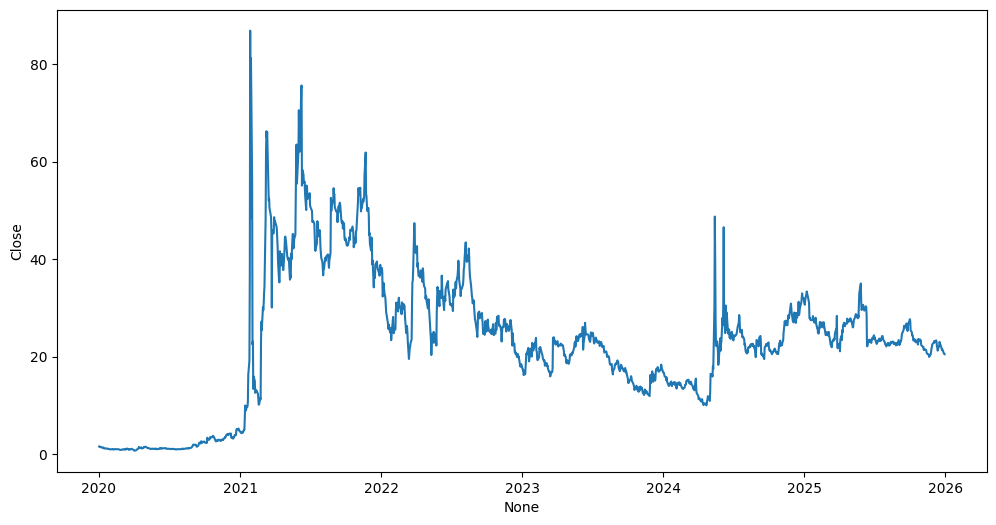

In [48]:
plt.figure(figsize=(12, 6))
sns.lineplot(x=df.index, y=df['Close'])
plt.show()

In [49]:
df['5MA'] = np.around(df['Close'].rolling(window=5).mean(), 0)
df.head()

,Open,High,Low,Close,Volume,Adj Close,5MA
2020-01-02,1.5350,1.6175,1.5175,1.5775,17814400,1.5775,NaN
2020-01-03,1.5525,1.5625,1.4600,1.4700,14175600,1.4700,NaN
2020-01-06,1.4500,1.4775,1.4000,1.4625,13579200,1.4625,NaN
2020-01-07,1.4425,1.4575,1.3600,1.3800,20912000,1.3800,NaN
2020-01-08,1.3725,1.4625,1.3525,1.4300,22517600,1.4300,1.0


## 데이터 분리

In [50]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size = 0.2, shuffle = False)
train.shape, test.shape

((1205, 7), (302, 7))

In [51]:
x_train = train.drop(['Close','Volume'], axis = 1)
y_train = train['Close']

In [52]:
x_train.shape, y_train.shape

((1205, 5), (1205,))

## 데이터 전처리
- 결측치
- 스케일링
- 타임스텝 데이터

In [53]:
x_train = x_train.dropna()
x_train.shape

(1201, 5)

In [54]:
y_train = y_train.loc[x_train.index]
y_train.shape

(1201,)

### 스케일링
- MInMax

In [55]:
from sklearn.preprocessing import MinMaxScaler

xms = MinMaxScaler()
x_train_s = xms.fit_transform(x_train)
x_train_s[:10]

array([[0.007 , 0.0061, 0.0098, 0.0085, 0.    ],
       [0.0079, 0.006 , 0.0101, 0.008 , 0.    ],
       [0.0072, 0.0055, 0.0097, 0.0076, 0.    ],
       [0.0068, 0.0056, 0.0096, 0.0076, 0.    ],
       [0.0051, 0.0043, 0.0068, 0.0055, 0.    ],
       [0.0048, 0.0037, 0.0069, 0.0053, 0.    ],
       [0.0047, 0.0037, 0.0067, 0.0053, 0.    ],
       [0.0046, 0.0038, 0.0067, 0.0057, 0.    ],
       [0.005 , 0.0038, 0.0069, 0.0052, 0.    ],
       [0.0045, 0.0035, 0.0065, 0.0051, 0.    ]])

In [56]:
yms = MinMaxScaler()
y_train_s = yms.fit_transform(y_train.to_numpy().reshape(-1,1))
y_train_s[:10]

array([[0.0085],
       [0.008 ],
       [0.0076],
       [0.0076],
       [0.0055],
       [0.0053],
       [0.0053],
       [0.0057],
       [0.0052],
       [0.0051]])

###시퀀스 데이터 셋

In [57]:
def make_sequence_dataset(X, y, window_size = 20):
  x_list = []
  y_list = []

  for i in range(len(X) - window_size):
    x_list.append(X[i:i+window_size])
    y_list.append(y[i+window_size])

  return np.array(x_list), np.array(y_list)

In [58]:
WINDOW_SIZE = 20
x_train_ss, y_train_ss = make_sequence_dataset(x_train_s, y_train_s, WINDOW_SIZE)
x_train_ss.shape, y_train_ss.shape

((1181, 20, 5), (1181, 1))

In [59]:
from keras import layers

model = keras.models.Sequential([
    keras.Input(shape=(20,5)),
    layers.LSTM(units=64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(units = 1, activation = None)
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,033 (78.25 KB)

 Trainable params: 20,033 (78.25 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
model.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mse']
)

In [61]:
EPOCHS = 30
BATCH_SIZE = 32

history = model.fit(x_train_ss,y_train_ss,
                    epochs=EPOCHS,
                    batch_size=BATCH_SIZE,
                    validation_split=0.2,
                    verbose=1)

Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0949 - mse: 0.0949 - val_loss: 0.0016 - val_mse: 0.0016
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0052 - mse: 0.0052 - val_loss: 0.0014 - val_mse: 0.0014
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0040 - mse: 0.0040 - val_loss: 0.0015 - val_mse: 0.0015
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0037 - mse: 0.0037 - val_loss: 0.0014 - val_mse: 0.0014
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0034 - mse: 0.0034 - val_loss: 0.0014 - val_mse: 0.0014
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0031 - mse: 0.0031 - val_loss: 0.0013 - val_mse: 0.0013
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0029 - mse: 0.0029 - val_loss: 0.0012 - val_mse: 0.0012
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0027 - mse: 0.0027 - val_loss: 0.0012 - val_mse: 0.0012
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.002

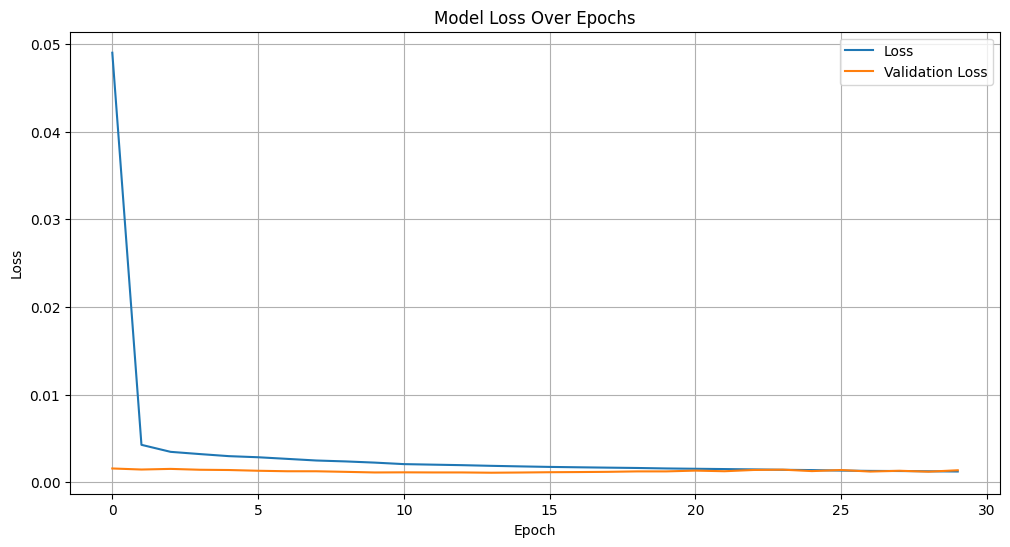

In [62]:
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

#테스트 데이터 전처리

In [63]:
x_test = test.drop(['Close', 'Volume'], axis = 1)
y_test = test['Close']

x_test = x_test.dropna()
y_test = y_test.loc[x_test.index]

x_test_s = xms.transform(x_test)
y_test_s = yms.transform(y_test.to_numpy().reshape(-1,1))

x_test_ss, y_test_ss = make_sequence_dataset(x_test_s, y_test_s, WINDOW_SIZE)

In [64]:
y_pred = model.predict(x_test_ss)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


### 모델 예측 결과 평가 및 시각화

`y_pred`와 `y_test_ss`는 연속적인 주가 예측 값이므로, **Confusion Matrix**는 분류 모델에 사용되는 지표라 여기에 적합하지 않습니다. 대신 **회귀 모델 평가 지표**와 **시계열 그래프**를 사용하여 예측 성능을 평가하고 시각화합니다.

먼저, 스케일링된 예측값과 실제값을 원래의 주가 스케일로 되돌립니다(`inverse_transform`).

In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 예측값과 실제값을 원래 스케일로 되돌리기
y_pred_original = yms.inverse_transform(y_pred)
y_test_original = yms.inverse_transform(y_test_ss)

# 회귀 성능 지표 계산
mae = mean_absolute_error(y_test_original, y_pred_original)
mse = mean_squared_error(y_test_original, y_pred_original)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_pred_original)

print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')
print(f'R-squared (R2): {r2:.4f}')

Mean Absolute Error (MAE): 0.9034
Mean Squared Error (MSE): 1.6215
Root Mean Squared Error (RMSE): 1.2734
R-squared (R2): 0.8291


### 예측값과 실제값 시각화

테스트 데이터셋의 실제 주가와 모델이 예측한 주가를 시계열 그래프로 비교합니다.

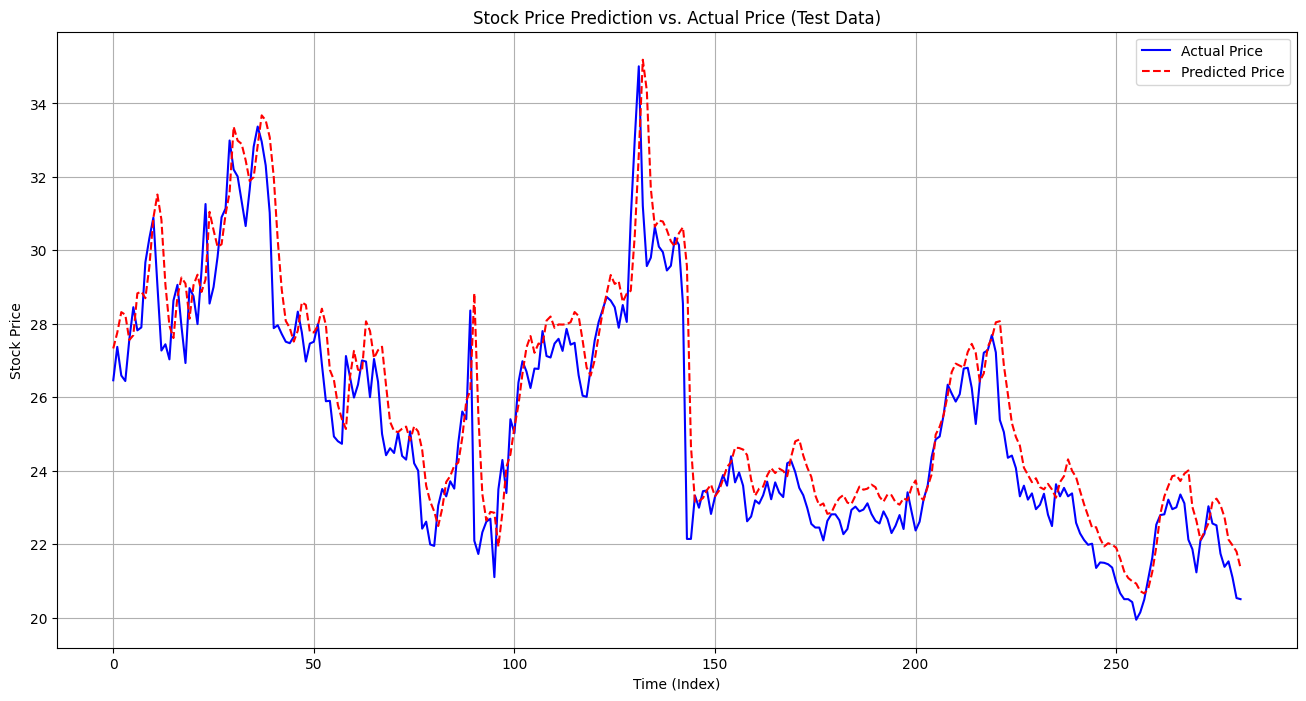

In [66]:
plt.figure(figsize=(16, 8))
plt.plot(y_test_original, label='Actual Price', color='blue')
plt.plot(y_pred_original, label='Predicted Price', color='red', linestyle='--')
plt.title('Stock Price Prediction vs. Actual Price (Test Data)')
plt.xlabel('Time (Index)')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)
plt.show()

### 예측값과 실제값 산점도 시각화

예측값과 실제값의 산점도를 통해 모델의 전반적인 경향성을 파악할 수 있습니다. 이상적인 예측이라면 모든 점이 대각선(`y=x`)에 가깝게 분포해야 합니다.

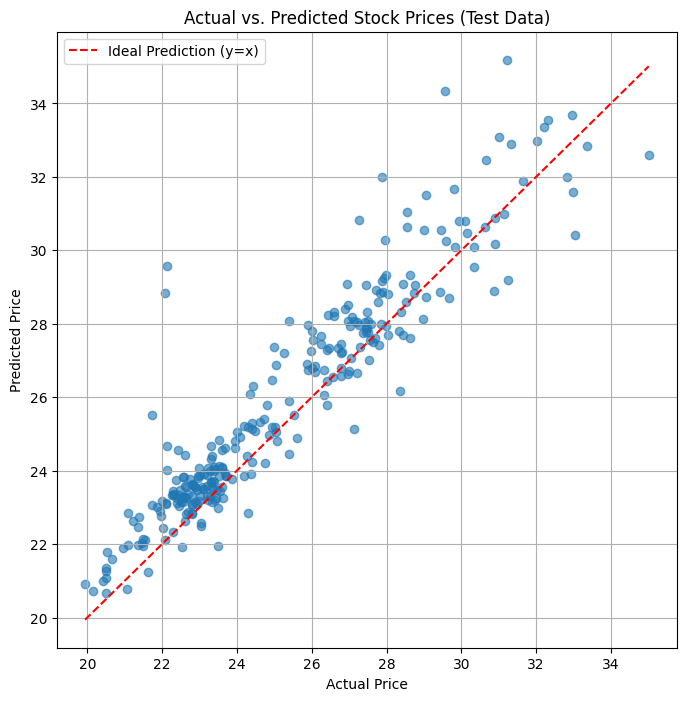

In [67]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test_original, y_pred_original, alpha=0.6)
plt.plot([min(y_test_original), max(y_test_original)], [min(y_test_original), max(y_test_original)], linestyle='--', color='red', label='Ideal Prediction (y=x)')
plt.title('Actual vs. Predicted Stock Prices (Test Data)')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.grid(True)
plt.show()